In [3]:
import pandas as pd
import numpy as np

In [4]:
#reading the train file
df = pd.read_csv('train.csv')
df.head()

,0,1,2,3,4,5,6,7,8,9,...,44,45,46,47,48,49,50,51,52,target
0,236,488,16,221,382,97,-4.472136,0.107472,0,132,...,13.340874,0.870542,1.962937,7.466666,11.547794,8.822916,9.046424,7.895535,11.010677,20.107472
1,386,206,357,232,1,198,7.810250,0.763713,1,143,...,12.484882,7.168680,2.885415,12.413973,10.260494,10.091351,9.270888,3.173994,13.921871,61.763713
2,429,49,481,111,111,146,8.602325,0.651162,1,430,...,14.030257,0.394970,8.160625,12.592059,8.937577,2.265191,11.255721,12.794841,12.080951,74.651162
3,414,350,481,370,208,158,8.306624,0.424645,1,340,...,2.789577,6.416708,10.549814,11.456437,6.468099,2.519049,0.258284,9.317696,5.383098,69.424645
4,318,359,20,218,317,301,8.124038,0.767304,1,212,...,1.886560,1.919999,2.268203,0.149421,4.105907,10.416291,6.816217,8.586960,4.512419,66.767304


In [5]:
#checking nulls and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 54 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       90000 non-null  int64  
 1   1       90000 non-null  int64  
 2   2       90000 non-null  int64  
 3   3       90000 non-null  int64  
 4   4       90000 non-null  int64  
 5   5       90000 non-null  int64  
 6   6       90000 non-null  float64
 7   7       90000 non-null  float64
 8   8       90000 non-null  int64  
 9   9       90000 non-null  int64  
 10  10      90000 non-null  int64  
 11  11      90000 non-null  int64  
 12  12      90000 non-null  int64  
 13  13      90000 non-null  float64
 14  14      90000 non-null  float64
 15  15      90000 non-null  float64
 16  16      90000 non-null  float64
 17  17      90000 non-null  float64
 18  18      90000 non-null  float64
 19  19      90000 non-null  float64
 20  20      90000 non-null  float64
 21  21      90000 non-null  float64
 22

In [7]:
#more convenient way to see general statistics
df_stats_transposed = df.describe().T
df_stats_transposed["unique"] = df.nunique()
df_stats_transposed["dtype"] = df.dtypes

In [ ]:
#potential non-continuous variables
df_stats_transposed[df_stats_transposed['unique']<len(df)]

,count,mean,std,min,25%,50%,75%,max,unique,dtype
0,90000.0,249.423944,144.336393,0.000000,125.000000,250.0,374.0,499.000000,500,int64
1,90000.0,250.236267,144.022200,0.000000,126.000000,251.0,375.0,499.000000,500,int64
2,90000.0,248.637289,144.107577,0.000000,124.000000,248.0,374.0,499.000000,500,int64
3,90000.0,249.736600,144.284945,0.000000,125.000000,250.0,375.0,499.000000,500,int64
4,90000.0,249.436178,143.941581,0.000000,125.000000,250.0,373.0,499.000000,500,int64
5,90000.0,249.656167,144.329168,0.000000,124.000000,250.0,374.0,499.000000,500,int64
6,90000.0,-0.011402,7.038171,-9.949874,-7.071068,0.0,7.0,9.949874,199,float64
8,90000.0,0.499189,0.500002,0.000000,0.000000,0.0,1.0,1.000000,2,int64
9,90000.0,249.842033,144.612718,0.000000,124.000000,250.0,376.0,499.000000,500,int64
10,90000.0,249.818967,144.363827,0.000000,126.000000,250.0,375.0,499.000000,500,int64


In [ ]:
#to check continuous variables
df_stats_transposed[df_stats_transposed['unique']>500]

,count,mean,std,min,25%,50%,75%,max,unique,dtype
7,90000.0,0.498548,0.288682,0.000014,0.248932,0.497136,0.747513,0.999987,90000,float64
13,90000.0,7.483940,4.330908,0.000095,3.723392,7.483265,11.242883,14.999920,90000,float64
14,90000.0,7.498037,4.318388,0.000252,3.763626,7.505267,11.228331,14.999938,90000,float64
15,90000.0,7.496259,4.338732,0.000190,3.718755,7.502682,11.258049,14.999660,90000,float64
16,90000.0,7.501635,4.345618,0.000192,3.719537,7.515240,11.284618,14.999979,90000,float64
17,90000.0,7.486463,4.318031,0.000067,3.758746,7.467721,11.238904,14.999840,90000,float64
18,90000.0,7.523043,4.323500,0.000229,3.778857,7.539462,11.254751,14.999857,90000,float64
19,90000.0,7.475585,4.327327,0.000125,3.733780,7.460267,11.211187,14.999634,90000,float64
20,90000.0,7.494835,4.325447,0.000382,3.748951,7.481500,11.238128,14.999953,90000,float64
21,90000.0,7.503939,4.330159,0.000398,3.760261,7.521563,11.248749,14.999483,90000,float64


From the preliminary exploration, columns 0-5 and 9-12 look like categories or ordered data like rating of some sort as they have exactly 500 unique values and int64 data type. Column 8 is boolean since it contains only 0s and 1s. Column 6 has float64 but the same absolute value of max and min, as well almost identical absolute values of 25th and 75th percentile, and 199 unique values.

Other columns have number of unique values = len(df), and type float64. Column 7 differs from other feature columns having value range between 0.000014 to 0.999987, while all other columns from 13th to 52nd have similar ranges from around 0 to 14.99, with similar stndard deviations, means and percentiles. That could mean that these variables are highly correlated, however, does not necessary implies.

In [8]:
#from statistical measures distribution for most of the variables looks quite symmetrical, calculating skewness to be sure
from scipy.stats import skew, kurtosis

df_stats_transposed["skewness"] = df.apply(skew)
df_stats_transposed["excess_kurtosis"] = df.apply(kurtosis)

In [10]:
df_stats_transposed[['skewness', 'excess_kurtosis']].describe()

,skewness,excess_kurtosis
count,54.000000,54.000000
mean,0.000305,-1.222743
std,0.005239,0.124701
min,-0.007765,-1.999989
25%,-0.004129,-1.201503
50%,-0.000430,-1.199458
75%,0.003542,-1.196992
max,0.012643,-1.192255


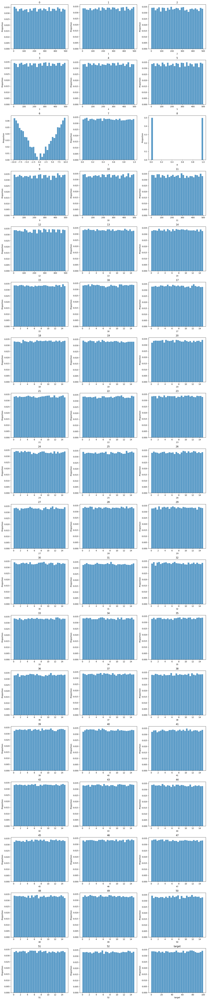

In [11]:
#outputs are collapsed since here I plot histograms for all columns 
import matplotlib.pyplot as plt
import seaborn as sns
import math

cols = df.select_dtypes(include="number").columns

n_cols = 3
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 4 * n_rows)
)
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        stat="probability",
        ax=axes[i],
        edgecolor="white"
    )
    axes[i].set_title(col)
    axes[i].set_ylabel("Proportion")

# Hide unused subplots
for i in range(len(cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

From the histograms above, almost all variable including target follow uniform distribution with only column 9 forming V-shaped distribution.

In [12]:
#based on previous observations, the columns are assigned the type to proceed with correlation coefficients calculation
binary_col = ["8"]

continuous_cols = ['6', '7', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24',
       '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36',
       '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48',
       '49', '50', '51', '52']

categorical_cols = ['0', '1', '2', '3', '4', '5', '9', '10', '11', '12']

Most of the variables have symmetric distributions with lighter than normal distribution tales. I will use spearman coefficient to catch possible monotonous but non-linear relationships between features. To calculate correlation coefficients between categorical columns, I will use Cramer's V.

In [13]:
continuous_corr = df[continuous_cols].corr(method="spearman")

In [ ]:
#function to calculate cramer's v 
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    data = pd.DataFrame({"x": x, "y": y}).dropna()

    if len(data) == 0:
        return np.nan

    table = pd.crosstab(data["x"], data["y"])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()

    # Bias-corrected Cramer's V
    phi2 = chi2 / n
    r, k = table.shape

    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    ) if n > 1 else 0

    r_corr = r - ((r - 1) ** 2) / (n - 1) if n > 1 else r
    k_corr = k - ((k - 1) ** 2) / (n - 1) if n > 1 else k

    denominator = min(k_corr - 1, r_corr - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denominator)

In [15]:
#constructing correlation matrix for categorical values
categorical_assoc = pd.DataFrame(
    np.eye(len(categorical_cols)),
    index=categorical_cols,
    columns=categorical_cols,
)

for i, col1 in enumerate(categorical_cols):
    for col2 in categorical_cols[i + 1:]:
        v = cramers_v(df[col1], df[col2])
        categorical_assoc.loc[col1, col2] = v
        categorical_assoc.loc[col2, col1] = v

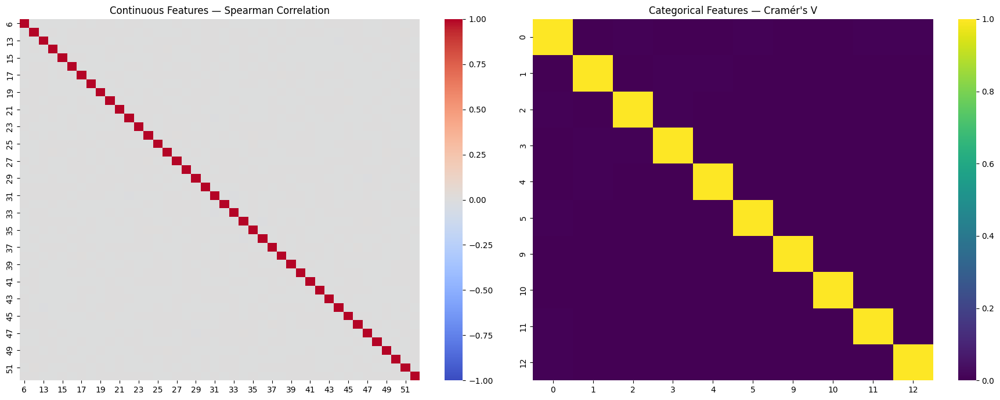

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    continuous_corr,
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    ax=axes[0]
)
axes[0].set_title("Continuous Features — Spearman Correlation")

sns.heatmap(
    categorical_assoc,
    cmap="viridis",
    vmin=0, vmax=1,
    ax=axes[1]
)
axes[1].set_title("Categorical Features — Cramér's V")

plt.tight_layout()
plt.show()

Although many continuous and categorical columns have similar value ranges and distribution shapes, none of the continuous variables correlate with each other. Same holds for categorical variables. That could mean that variables are completely independent or that they have non-linear non-monotonous relationship.

In [17]:
# it is also worth to check correlations between comtinuous independent variables and target variable
target_col = "target"

numeric_cols = (
    df.select_dtypes(include="number")
    .columns
    .drop(target_col, errors="ignore")
)

target_corr = (
    df[numeric_cols]
    .corrwith(df[target_col], method="spearman")
    .sort_values(key=abs, ascending=False)
)

In [18]:
#checking if there are any correlations
target_corr[target_corr>0.1]

Series([], dtype: float64)

Since Spearman did not catch any monotonous relationship between variables and targets, let's plot each independent variable against target

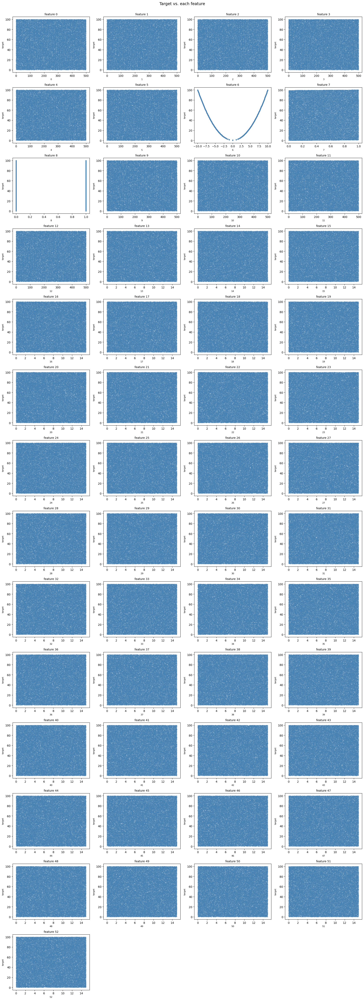

In [20]:
import math
import matplotlib.pyplot as plt

feature_cols = [c for c in df.columns if c != target_col]

n_cols = 4
n_rows = math.ceil(len(feature_cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 3.5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    ax.scatter(df[col], df["target"], s=2, alpha=0.2, color="steelblue")
    ax.set_title(f"feature {col}", fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel("target", fontsize=8)

# Hide unused subplots
for ax in axes[len(feature_cols):]:
    ax.set_visible(False)

fig.suptitle("Target vs. each feature", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

Here, we can clearly see that column 8 has a non-monotnous quadratic relationship to target. Other columns appear to not have any relationship at all. Let's also check mutual information, to be sure there are no other columns relevant to target.

In [35]:
from sklearn.feature_selection import mutual_info_regression

feature_cols = [c for c in df.columns if c != target_col]

mi_scores = mutual_info_regression(df[feature_cols], df[target_col], random_state=42)

mi_series = pd.Series(mi_scores, index=feature_cols, name="mutual_info").sort_values(ascending=False)

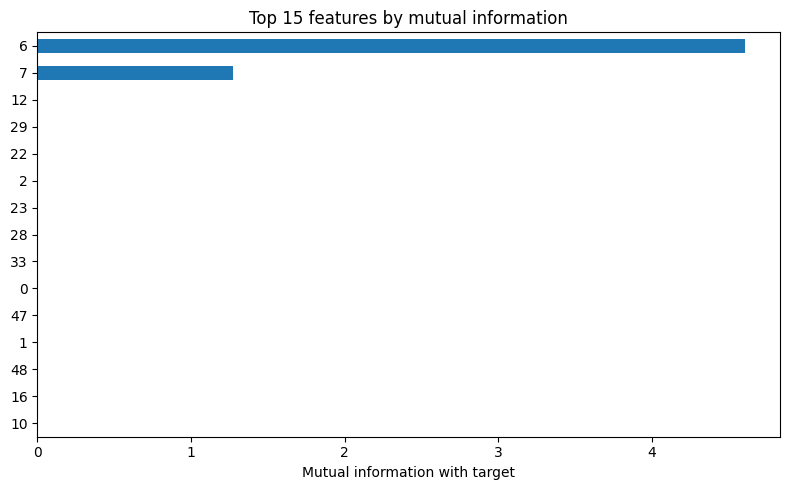

In [ ]:
#plotting top-15 features
import matplotlib.pyplot as plt

top = mi_series.head(15)
plt.figure(figsize=(8, 5))
top[::-1].plot(kind="barh")
plt.xlabel("Mutual information with target")
plt.title("Top 15 features by mutual information")
plt.tight_layout()
plt.show()

From the mutual information plot, we can see that only columns 6 and 7 carry a meaningful amount of information about the target (MI ≈ 4.6 and ≈ 1.3 respectively), while all other features score below 0.01, which is the noise level expected from the estimator. This suggests that the remaining 51 features are irrelevant and can be considered for removal during feature selection.

Since we have a quadratic relationship between column 6 and target, it makes sense to use (column 6)^2 to fit linear regression. Since we do not observe such relationship between column column 7 and target, but it still has some predictive power, I will leave it as is.

In [33]:
df['6_squared'] = df['6']**2

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor


X = df[['6_squared', '7']].copy()
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(
    X_test
)

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print("Test MAE:", mean_absolute_error(y_test, predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test R²:", r2_score(y_test, predictions))

print("\nBaseline results")
print("MAE:", mean_absolute_error(y_test, baseline_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, baseline_predictions)))
print("R²:", r2_score(y_test, baseline_predictions))

Test MAE: 1.0136318862774243e-13
Test RMSE: 1.170856774476421e-13
Test R²: 1.0

Baseline results
MAE: 25.0739194114648
RMSE: 28.92671735652493
R²: -0.00012190485573682075
